<a href="https://colab.research.google.com/github/Aigulya0/eda-titanic-variant-b/blob/main/Practical_2_EDA_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Датасет успешно загружен!")
print("Размер таблицы:", df.shape)

display(df.head())

Датасет успешно загружен!
Размер таблицы: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
print("Первые 5 строк:")
display(df.head())

print("Последние 5 строк:")
display(df.tail())

Первые 5 строк:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Последние 5 строк:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [3]:
print("Количество строк и столбцов:", df.shape)

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nИнформация о таблице:")
df.info()


Количество строк и столбцов: (891, 15)

Названия столбцов:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Информация о таблице:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    obj

In [4]:
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("ЧИСЛОВЫЕ ПРИЗНАКИ:")
print(numeric_cols)

print("\nКАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ:")
print(categorical_cols)

print("\nКоличество числовых признаков:", len(numeric_cols))
print("Количество категориальных признаков:", len(categorical_cols))

ЧИСЛОВЫЕ ПРИЗНАКИ:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Количество числовых признаков: 6
Количество категориальных признаков: 9


In [5]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)

missing_table = pd.DataFrame({
    "Пропусков": missing_count,
    "Процент пропусков": missing_percent
})

missing_table = missing_table.sort_values(
    by="Пропусков",
    ascending=False
)

display(missing_table)

,Пропусков,Процент пропусков
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


In [6]:
print("Количество полностью одинаковых строк:", df.duplicated().sum())
print("Количество уникальных строк:", len(df.drop_duplicates()))

Количество полностью одинаковых строк: 107
Количество уникальных строк: 784


In [7]:
display(df[numeric_cols].describe().round(2))

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


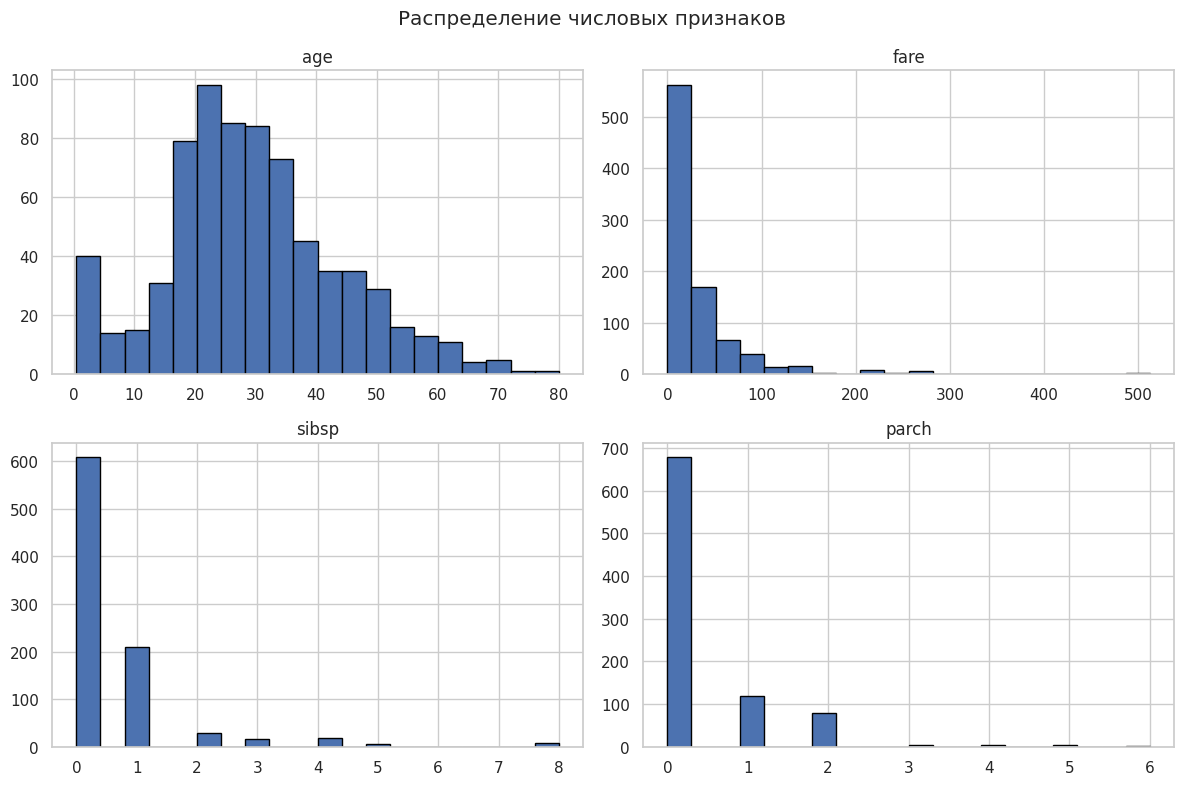

In [8]:
plot_cols = ["age", "fare", "sibsp", "parch"]

df[plot_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Распределение числовых признаков")
plt.tight_layout()
plt.show()

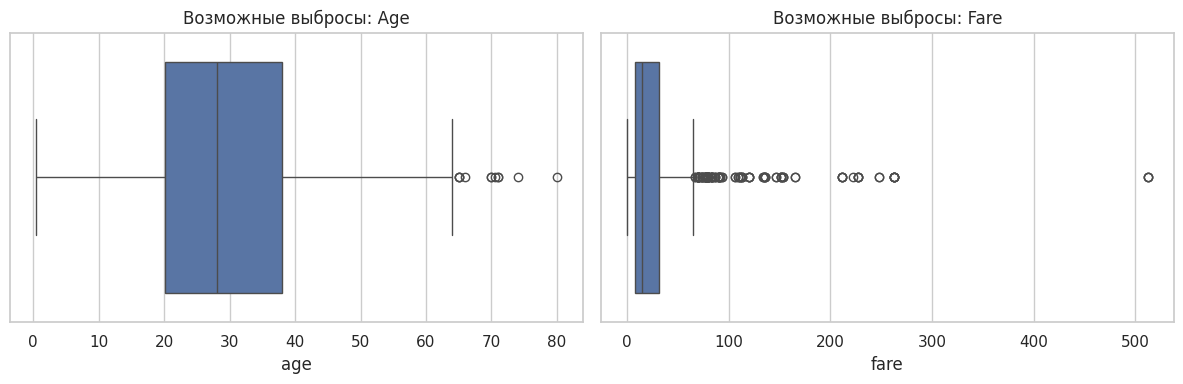

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="age", ax=axes[0])
axes[0].set_title("Возможные выбросы: Age")

sns.boxplot(data=df, x="fare", ax=axes[1])
axes[1].set_title("Возможные выбросы: Fare")

plt.tight_layout()
plt.show()

In [10]:
for col in ["age", "fare", "sibsp", "parch"]:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = values[(values < lower) | (values > upper)]

    print(f"\nСтолбец: {col}")
    print("Нижняя граница:", round(lower, 2))
    print("Верхняя граница:", round(upper, 2))
    print("Количество потенциальных выбросов:", len(outliers))


Столбец: age
Нижняя граница: -6.69
Верхняя граница: 64.81
Количество потенциальных выбросов: 11

Столбец: fare
Нижняя граница: -26.72
Верхняя граница: 65.63
Количество потенциальных выбросов: 116

Столбец: sibsp
Нижняя граница: -1.5
Верхняя граница: 2.5
Количество потенциальных выбросов: 46

Столбец: parch
Нижняя граница: 0.0
Верхняя граница: 0.0
Количество потенциальных выбросов: 213


In [11]:
for col in categorical_cols:
    print(f"\nСтолбец: {col}")
    print(df[col].value_counts(dropna=False).head(15))


Столбец: sex
sex
male      577
female    314
Name: count, dtype: int64

Столбец: embarked
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

Столбец: class
class
Third     491
First     216
Second    184
Name: count, dtype: int64

Столбец: who
who
man      537
woman    271
child     83
Name: count, dtype: int64

Столбец: adult_male
adult_male
True     537
False    354
Name: count, dtype: int64

Столбец: deck
deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64

Столбец: embark_town
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

Столбец: alive
alive
no     549
yes    342
Name: count, dtype: int64

Столбец: alone
alone
True     537
False    354
Name: count, dtype: int64


In [12]:
for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)
    rare = counts[counts < 10]

    print(f"\nСтолбец: {col}")
    if len(rare) > 0:
        print("Редкие категории:")
        print(rare)
    else:
        print("Категорий с частотой меньше 10 нет.")


Столбец: sex
Категорий с частотой меньше 10 нет.

Столбец: embarked
Редкие категории:
embarked
NaN    2
Name: count, dtype: int64

Столбец: class
Категорий с частотой меньше 10 нет.

Столбец: who
Категорий с частотой меньше 10 нет.

Столбец: adult_male
Категорий с частотой меньше 10 нет.

Столбец: deck
Редкие категории:
deck
G    4
Name: count, dtype: int64

Столбец: embark_town
Редкие категории:
embark_town
NaN    2
Name: count, dtype: int64

Столбец: alive
Категорий с частотой меньше 10 нет.

Столбец: alone
Категорий с частотой меньше 10 нет.


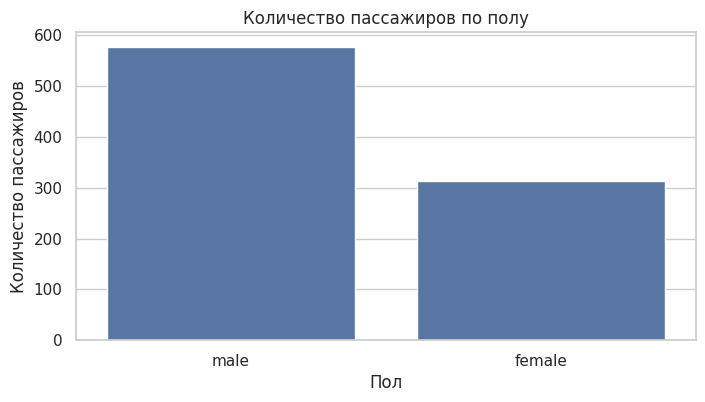

In [13]:
plt.figure(figsize=(8, 4))

sns.countplot(data=df, x="sex")

plt.title("Количество пассажиров по полу")
plt.xlabel("Пол")
plt.ylabel("Количество пассажиров")
plt.show()

In [14]:
corr = df[numeric_cols].corr()

display(corr.round(2))

,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.34,-0.08,-0.04,0.08,0.26
pclass,-0.34,1.00,-0.37,0.08,0.02,-0.55
age,-0.08,-0.37,1.00,-0.31,-0.19,0.10
sibsp,-0.04,0.08,-0.31,1.00,0.41,0.16
parch,0.08,0.02,-0.19,0.41,1.00,0.22
fare,0.26,-0.55,0.10,0.16,0.22,1.00


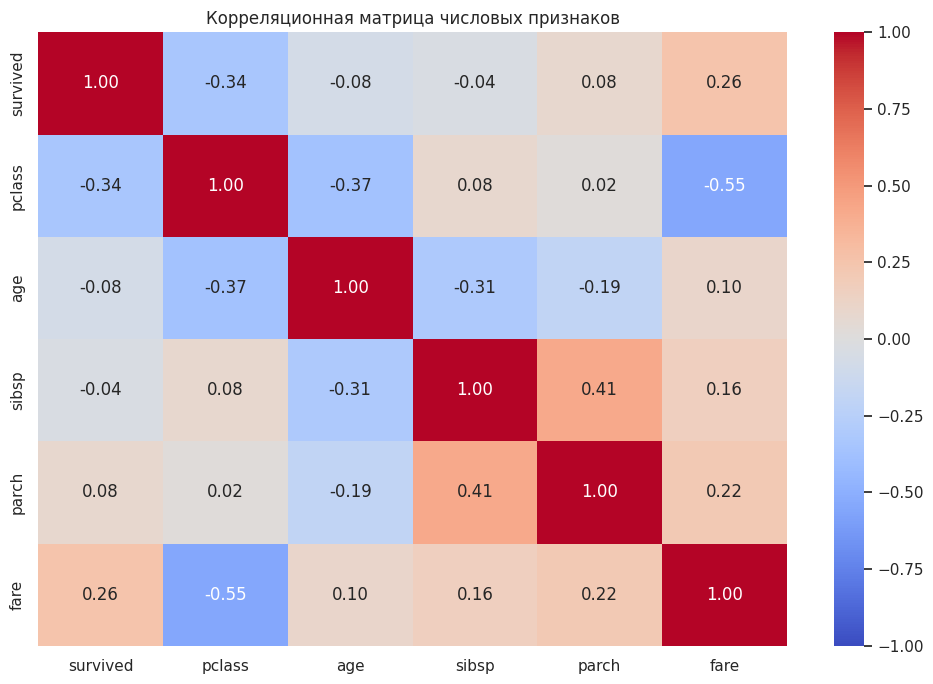

In [15]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

In [16]:
corr_abs = corr.abs()

upper_triangle = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

top_pairs = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
)

print("Три наиболее коррелирующие пары:")
display(top_pairs.head(3))

Три наиболее коррелирующие пары:


,,0
pclass,fare,0.549500
sibsp,parch,0.414838
pclass,age,0.369226


Выбранные признаки: ['pclass', 'fare', 'sibsp', 'parch', 'age']


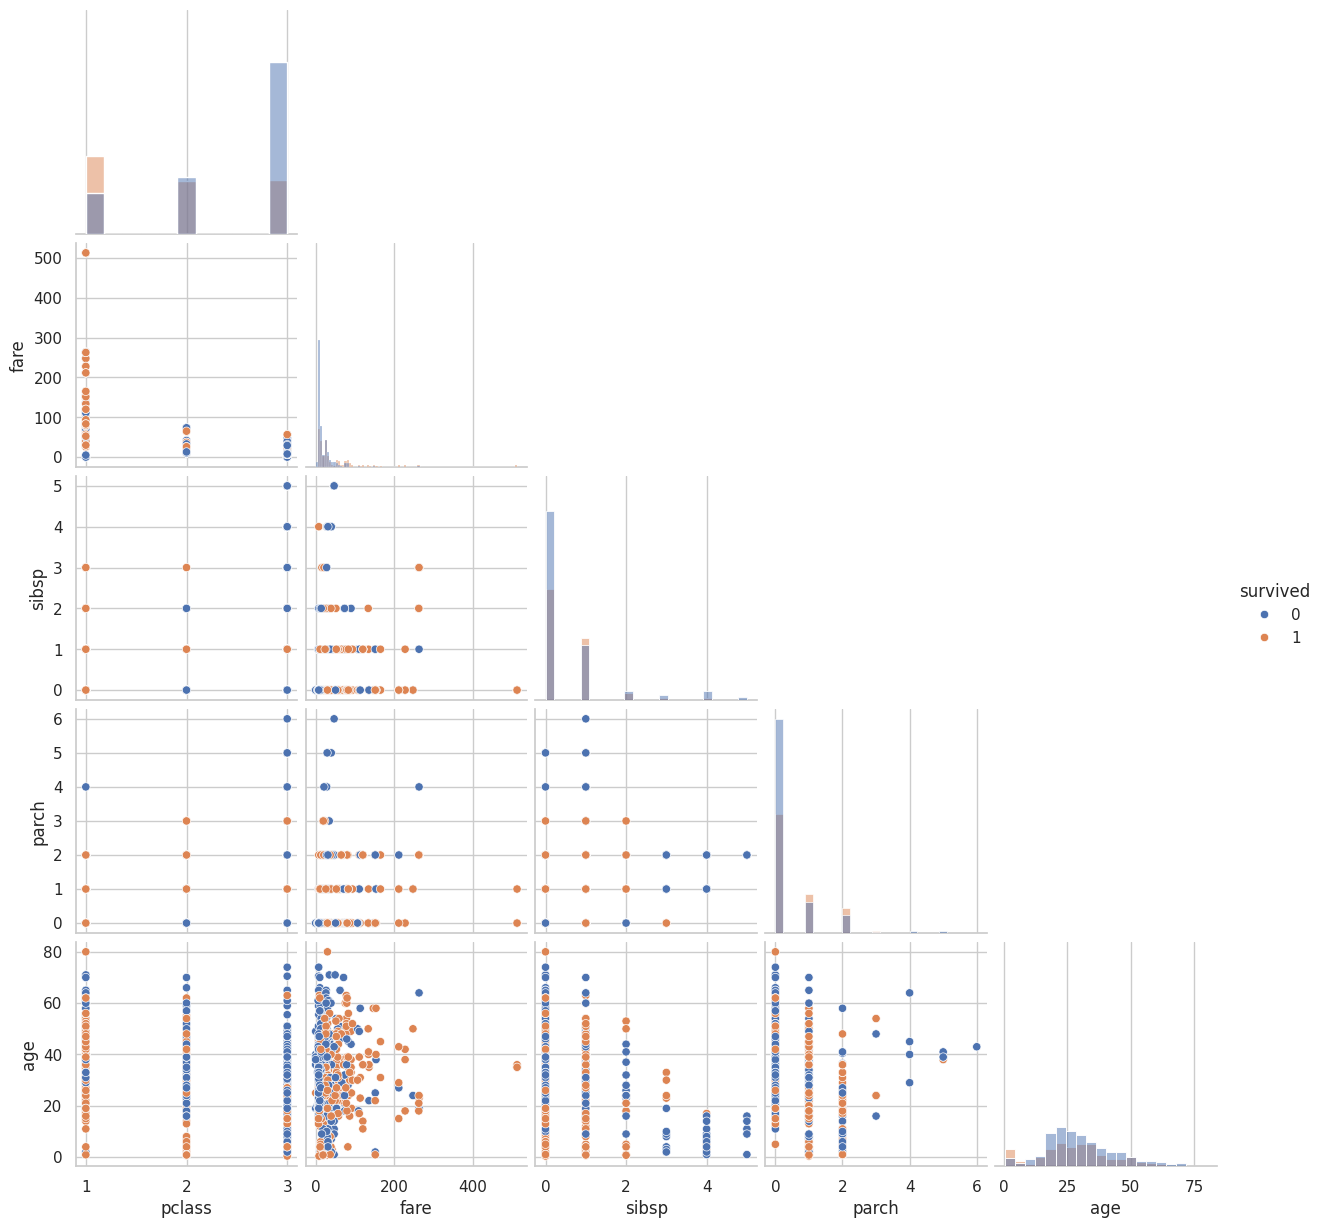

In [17]:
feature_cols = [
    col for col in numeric_cols
    if col != "survived"
]

feature_corr = df[feature_cols].corr().abs()

upper = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

top_feature_pairs = (
    upper.stack()
    .sort_values(ascending=False)
    .head(3)
)

selected_cols = list(dict.fromkeys(
    col
    for pair in top_feature_pairs.index
    for col in pair
))

print("Выбранные признаки:", selected_cols)

plot_df = df[selected_cols + ["survived"]].dropna()

sns.pairplot(
    plot_df,
    vars=selected_cols,
    hue="survived",
    diag_kind="hist",
    corner=True
)

plt.show()

In [18]:
target_counts = df["survived"].value_counts().sort_index()

target_percent = (
    df["survived"].value_counts(normalize=True).sort_index() * 100
).round(2)

target_table = pd.DataFrame({
    "Количество": target_counts,
    "Процент": target_percent
})

display(target_table)

,Количество,Процент
survived,,
0,549,61.62
1,342,38.38


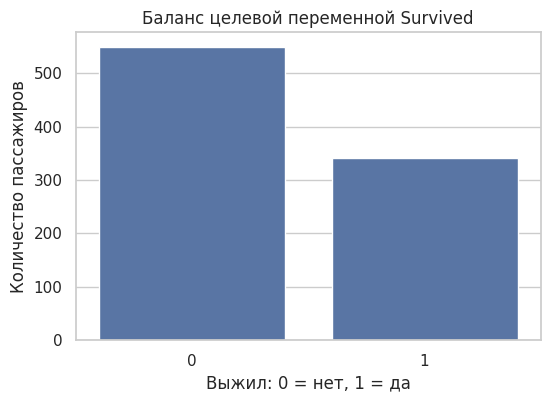

In [19]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="survived")

plt.title("Баланс целевой переменной Survived")
plt.xlabel("Выжил: 0 = нет, 1 = да")
plt.ylabel("Количество пассажиров")
plt.show()

# Отчёт по результатам EDA — Titanic

1. **Общая информация о данных.** Датасет содержит 891 строку и 15 столбцов. Признаки включают числовые и категориальные данные. Целевая переменная — `survived`.

2. **Пропущенные значения.** Пропуски обнаружены в столбцах: [впиши названия]. На следующем занятии планируется изучить причины пропусков и выбрать подходящий способ их обработки.

3. **Распределение числовых признаков.** По гистограммам выявлены особенности распределения признаков [впиши названия]. Для дальнейшего анализа необходимо учитывать асимметрию распределения, если она наблюдается.

4. **Потенциальные выбросы.** По диаграммам размаха и правилу IQR найдены потенциальные выбросы в признаках [впиши названия]. Необходимо проверить, являются ли они ошибками или реальными наблюдениями.

5. **Категориальные признаки.** В столбцах [впиши названия] обнаружены редкие категории. На следующем занятии будет рассмотрена целесообразность их объединения.

6. **Корреляции между признаками.** Наиболее сильные связи обнаружены между [впиши пары признаков]. Эти зависимости необходимо учитывать при дальнейшем анализе.

7. **Баланс целевой переменной.** Доля класса `0` составила [впиши процент]%, а класса `1` — [впиши процент]%. [Укажи, есть ли дисбаланс.] При построении модели классификации следует учитывать соотношение классов.

In [20]:
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Датасет загружен!")
print("Размер таблицы:", df.shape)

df.head()

Датасет загружен!
Размер таблицы: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
